## Python for Data Science - matplotlib

#### Importing pandas

In [1]:
import numpy as np
import pandas as pd

#### Reading a CSV file into a dataframe
###### In this example, the file is in the same directory folder, so we can use the file name 

In [2]:
df_students = pd.read_csv('StudentData.csv')
print(df_students)

         Name  StudyHours  Grade
0         Tom        10.0   72.0
1       Jerry         4.0   37.0
2      Mickey         8.0   56.0
3      Minnie         5.0   41.0
4      Johnny         3.0   22.0
5     Richard        11.0   76.0
6      Arthur         4.0   35.0
7     Goliath         2.0   11.0
8   Broadyway         3.0   19.0
9     MacBeth         3.0   24.0
10      Elisa         9.0   77.0
11     Ashoka        12.0   84.0
12     Anakin         1.0    6.0
13    Obi-wan         4.0   32.0
14      Omega         5.0   44.0
15      Gungi         NaN    NaN
16    Xanatos         NaN    NaN


#### Preparing data for analysis

In [3]:
# Removing null values
df_students = df_students.dropna(axis=0)

# Creating a variable containing a pass/fail series
passed = pd.Series(df_students.Grade >= 60)

# Adding the series to the dataframe
df_students = pd.concat([df_students, passed.rename('Passed')], axis = 1)

# Display dataframe
df_students

,Name,StudyHours,Grade,Passed
0,Tom,10.0,72.0,True
1,Jerry,4.0,37.0,False
2,Mickey,8.0,56.0,False
3,Minnie,5.0,41.0,False
4,Johnny,3.0,22.0,False
5,Richard,11.0,76.0,True
6,Arthur,4.0,35.0,False
7,Goliath,2.0,11.0,False
8,Broadyway,3.0,19.0,False
9,MacBeth,3.0,24.0,False


#### Importing pyplot from matplotlib  

In [4]:
from matplotlib import pyplot as plt

#### Creating, Formatting and Displaying a plot
###### This example returns a bar chart

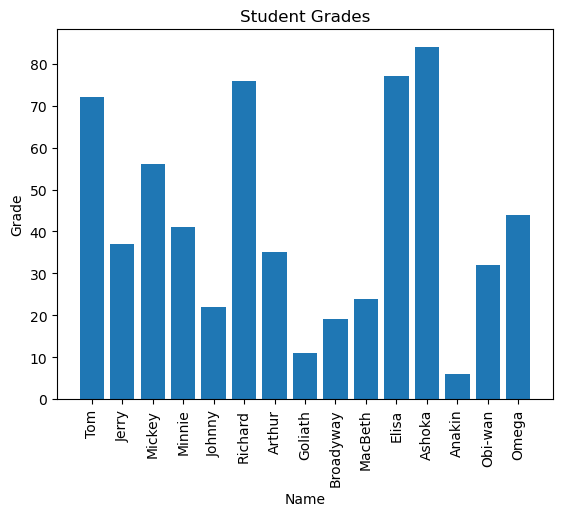

<Figure size 1280x720 with 0 Axes>

In [5]:
plt.bar(x = df_students.Name, height= df_students.Grade)

plt.title("Student Grades")
plt.xlabel("Name")
plt.ylabel("Grade")
plt.xticks(rotation=90)

fig = plt.figure(figsize=(12.8, 7.2))

#plt.show

#### Alternative, simplified syntax for creating, formatting, and displaying plots

<Axes: xlabel='Name'>

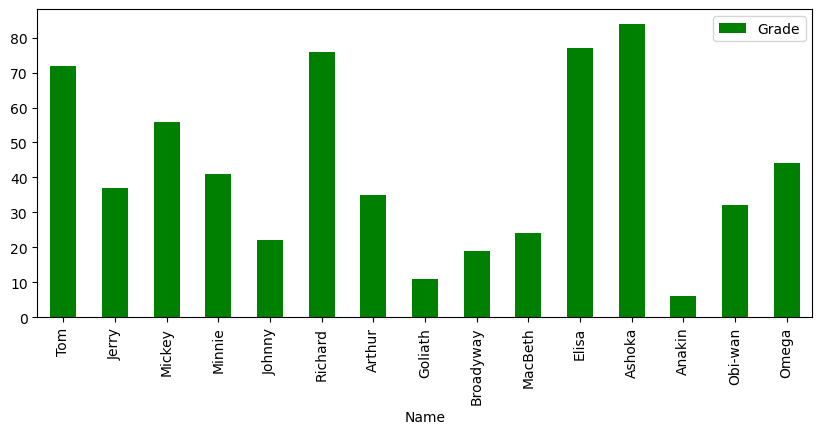

In [6]:
df_students.plot.bar(x='Name', y='Grade', figsize=(10,4), color = "green")

#### Displaying muliple plots in a single figure & Creating a pie chart

<bound method Figure.show of <Figure size 1000x400 with 2 Axes>>

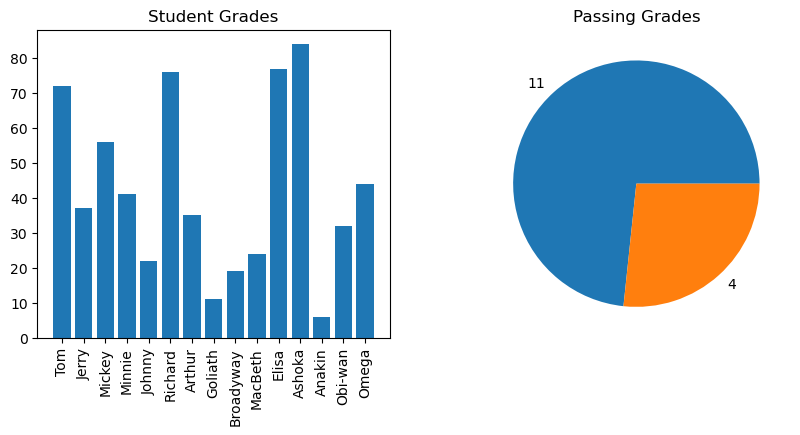

In [7]:
fig, ax = plt.subplots(1,2, figsize=(10, 4))

ax[0].bar(x = df_students.Name, height= df_students.Grade)

ax[0].set_title("Student Grades")
ax[0].set_xticks(df_students.Name)
ax[0].set_xticklabels(df_students.Name, rotation=90)

passes_count = df_students.Passed.value_counts()

ax[1].pie(passes_count, labels=passes_count)

ax[1].set_title("Passing Grades")

fig.show

#### Creating new variable & calculating descriptive statistics

In [8]:
grades = df_students.Grade

min_val= df_students.Grade.min()
max_val= df_students.Grade.max()
mean_val= df_students.Grade.mean()
med_val= df_students.Grade.median()
mode_val= df_students.Grade.mode()

print(f'Minimum: {min_val}\nMaximum: {max_val}\nMean: {mean_val}\nMedian: {med_val}')

Minimum: 6.0
Maximum: 84.0
Mean: 42.4
Median: 37.0


#### Defining a function that returns exploratory data analysis statistics 

In [9]:
def show_eda(var_data):
    min_val= var_data.min()
    max_val= var_data.max()
    mean_val= var_data.mean()
    med_val= var_data.median()
    mode_val= var_data.mode()

    print(f'Minimum: {min_val}\nMaximum: {max_val}\nMean: {mean_val}\nMedian: {med_val}\nMode: {mode_val} ')

show_eda(df_students.Grade)

Minimum: 6.0
Maximum: 84.0
Mean: 42.4
Median: 37.0
Mode: 0      6.0
1     11.0
2     19.0
3     22.0
4     24.0
5     32.0
6     35.0
7     37.0
8     41.0
9     44.0
10    56.0
11    72.0
12    76.0
13    77.0
14    84.0
Name: Grade, dtype: float64 


#### Calling the function and passing 'StudyHours' to it as an argument

In [10]:
show_eda(df_students.StudyHours)

Minimum: 1.0
Maximum: 12.0
Mean: 5.6
Median: 4.0
Mode: 0    3.0
1    4.0
Name: StudyHours, dtype: float64 


#### Using the .describe( ) function to return exploratory data analysis statistics

In [11]:
grades.describe()

count    15.00000
mean     42.40000
std      25.25244
min       6.00000
25%      23.00000
50%      37.00000
75%      64.00000
max      84.00000
Name: Grade, dtype: float64

#### Creating a formatted histogram

Text(0, 0.5, 'Frequency')

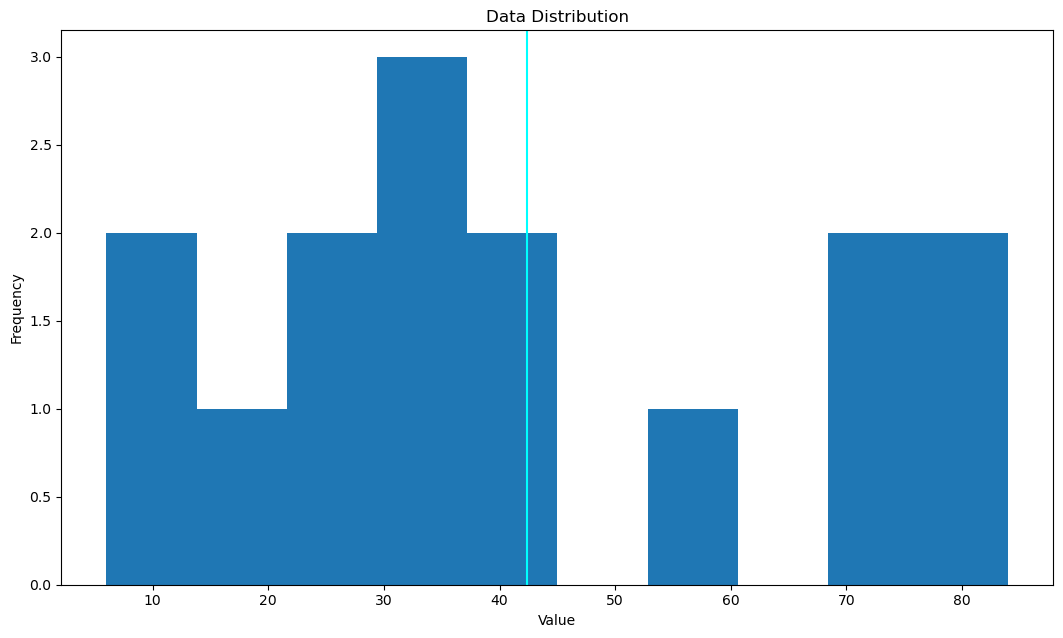

In [12]:
display(fig = plt.figure(figsize=(12.8,7.2)))

plt.hist(grades)

plt.axvline(x=mean_val, color='cyan')

plt.title("Data Distribution")
plt.xlabel("Value")
plt.ylabel("Frequency")


#### Defining a function which returns a formatted histogram, calling it, and passing the grades variable to it as an argument 

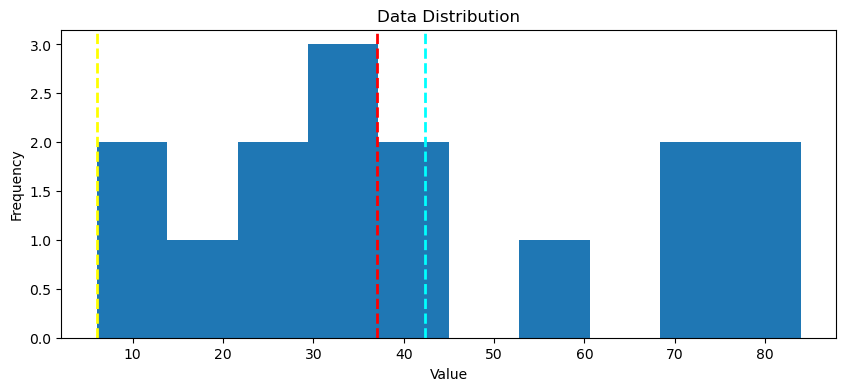

In [13]:
def show_histogram(var_data):
    
    fig = plt.figure(figsize=(10,4))

    plt.hist(var_data)

    plt.axvline(x=var_data.mean(), color='cyan', linestyle = 'dashed', linewidth = 2)
    plt.axvline(x=var_data.median(), color='red', linestyle = 'dashed', linewidth = 2)
    plt.axvline(x=var_data.mode()[0], color='yellow', linestyle = 'dashed', linewidth = 2)

    plt.title("Data Distribution")
    plt.xlabel("Value")
    plt.ylabel("Frequency")

    fig.show

show_histogram(grades)

#### Creating a boxplot

Text(0.5, 1.0, 'Data Distribution')

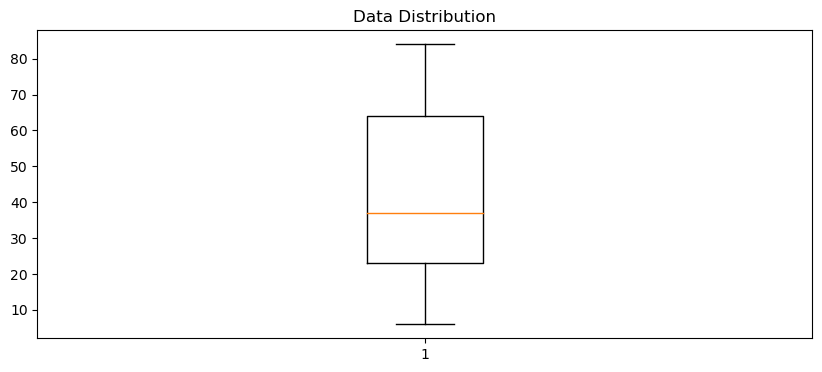

In [14]:
display(fig = plt.figure(figsize=(10, 4)))

plt.boxplot(grades)

plt.title("Data Distribution")

#### Defining a function which returns a figure with multiple subplots for analyzing the distribution of the data

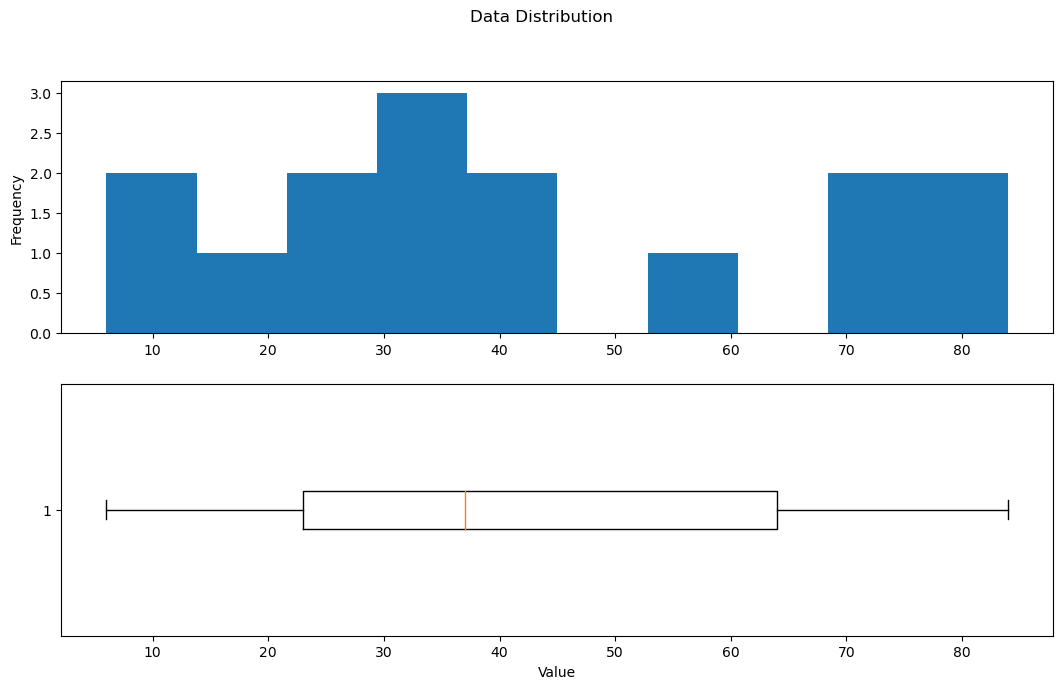

In [15]:
def show_distribution(var_data):

    fig, ax = plt.subplots(2,1, figsize=(12.8, 7.2))

    ax[0].hist(var_data)
    ax[0].set_ylabel("Frequency")

    ax[1].boxplot(var_data, vert=False)

    ax[1].set_xlabel('Value')

    fig.suptitle("Data Distribution")

    fig.show

show_distribution(df_students.Grade)

#### Defining a function whixh returns a plot of the data's density 

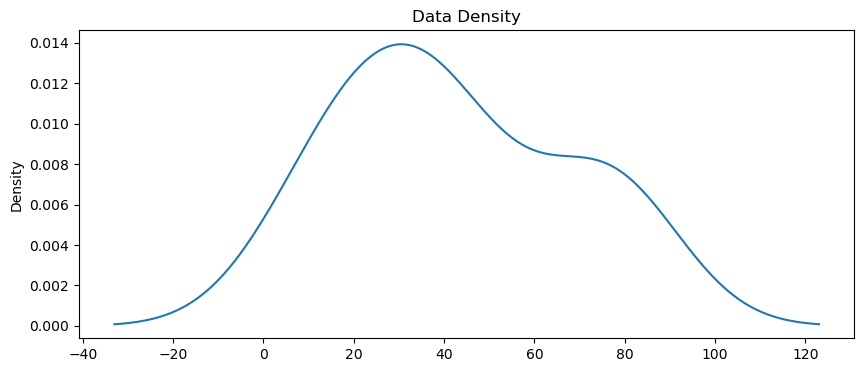

In [16]:
def show_density(data):
    fig = plt.figure(figsize=(10,4))

    data.plot.density()

    plt.title('Data Density')
    
    plt.show

show_density(df_students.Grade)

#### Calling the show_distrubution function and passing 'StudyHours' to it as an argument

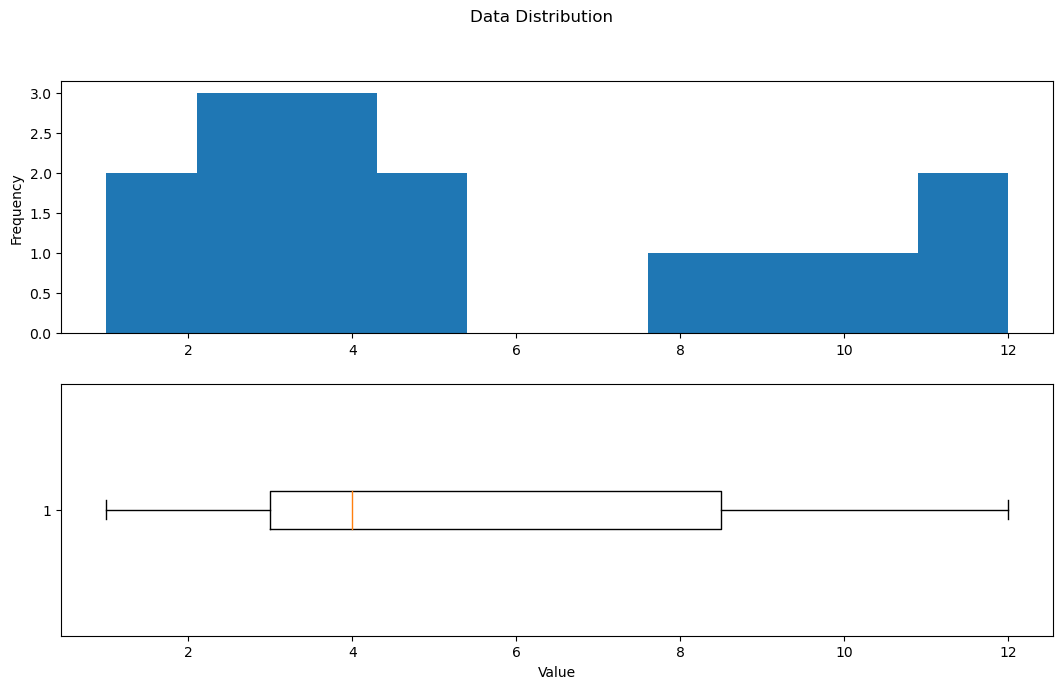

In [17]:
show_distribution(df_students.StudyHours)

#### Calling the show_density function and passing 'StudyHours' to it as an argument 

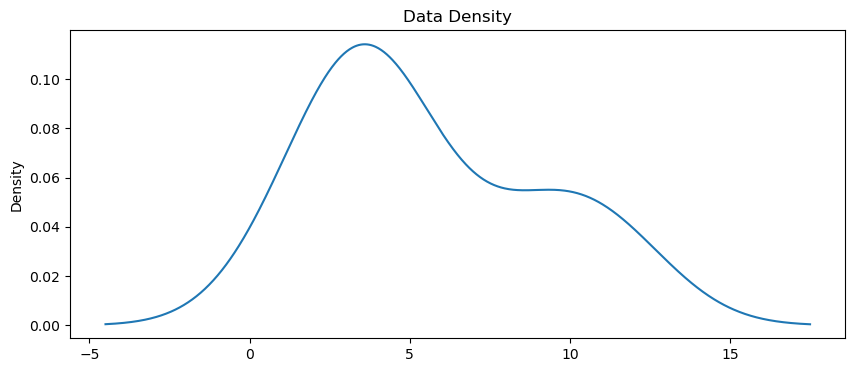

In [18]:
show_density(df_students.StudyHours)

In [19]:
df_students.describe()

,StudyHours,Grade
count,15.000000,15.00000
mean,5.600000,42.40000
std,3.480558,25.25244
min,1.000000,6.00000
25%,3.000000,23.00000
50%,4.000000,37.00000
75%,8.500000,64.00000
max,12.000000,84.00000


#### Using the .describe( ) function to return eda statistics for 'Grade'

In [20]:
df_students.Grade.describe()

count    15.00000
mean     42.40000
std      25.25244
min       6.00000
25%      23.00000
50%      37.00000
75%      64.00000
max      84.00000
Name: Grade, dtype: float64

#### Creating a figure which contains a table as a subplot

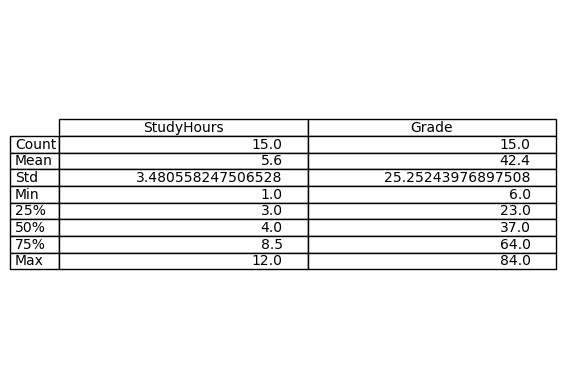

In [21]:
stats = df_students.describe()

# Create a figure and axis object
fig, ax = plt.subplots()

# Add the stats table to the figure
ax.table(cellText=stats.values,
         colLabels=stats.columns,
         rowLabels = ['Count', 'Mean', 'Std', 'Min', '25%', '50%', '75%', 'Max'],
         loc='center')

# Remove axis ticks and labels
ax.axis('off')

# Show the figure
plt.show()

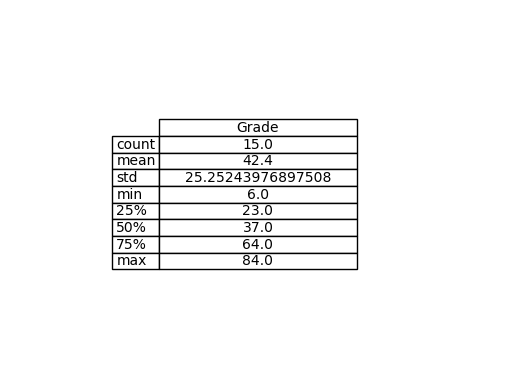

In [22]:
fig, ax = plt.subplots()
ax.axis('off')
table = pd.plotting.table(ax, df_students.Grade.describe(), loc='center', cellLoc='center', colWidths=list([.4, .4]))
plt.show()

#### Creating a Boxplot to compare the StudyHours of students who passed vs those who failed

<Axes: title={'center': 'StudyHours'}, xlabel='Passed'>

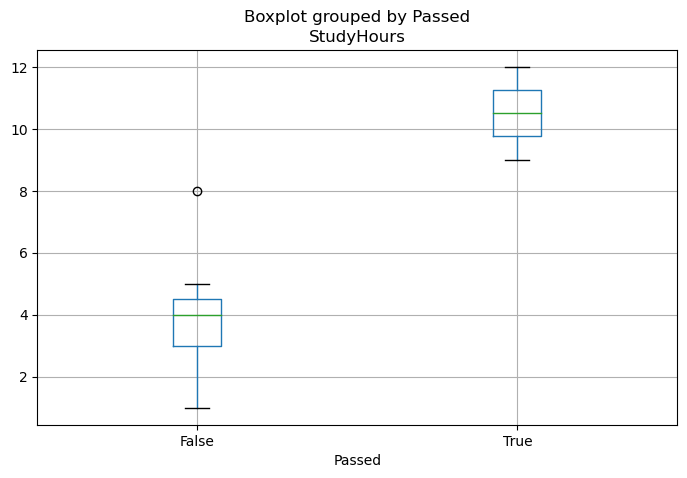

In [23]:
df_students.boxplot(column= 'StudyHours', by = 'Passed', figsize =(8,5))

#### Import sklearn 'Preprocessing'/Use .copy( ) method to create a new dataframe/Normalize the dataframe/Crate bar chart using new dataframe

<Axes: xlabel='Name'>

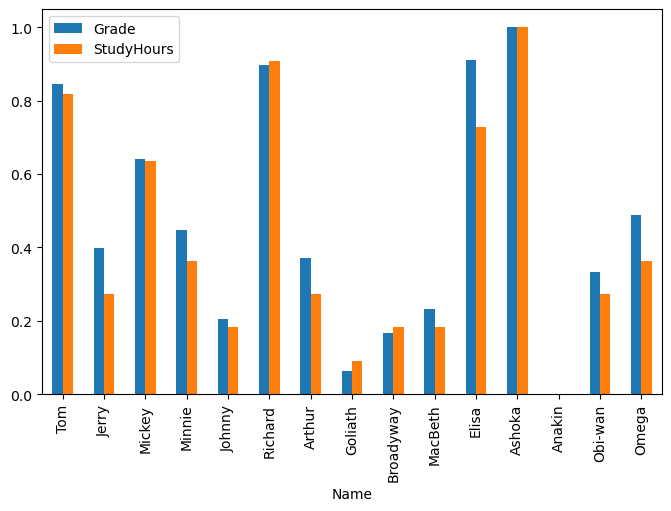

In [24]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

df_normalized = df_students[['Name','StudyHours', 'Grade']].copy()

df_normalized[['StudyHours', 'Grade']] = scaler.fit_transform(df_normalized[['StudyHours', 'Grade']])

df_normalized.plot(x='Name', y= ['Grade', 'StudyHours'], kind = 'bar', figsize=(8,5) )

#### Find the correlation value between Grade and StudyHours

In [25]:
df_normalized.Grade.corr(df_students.StudyHours)

0.981230153628497

#### Creating a scatterplot to analyze correlation

<Axes: title={'center': 'StudyHours vs Grade'}, xlabel='StudyHours', ylabel='Grade'>

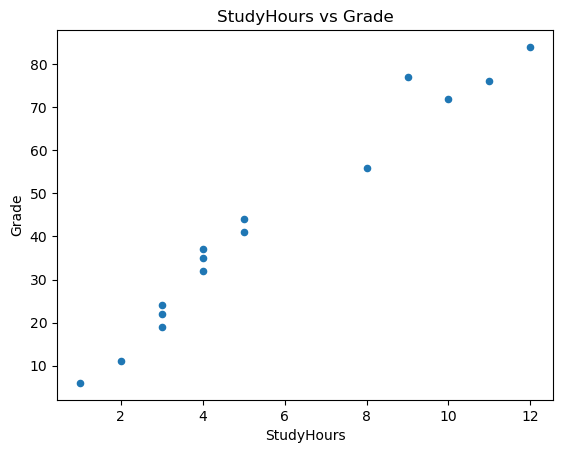

In [26]:
df_students.plot.scatter(title='StudyHours vs Grade', x='StudyHours', y='Grade')

#### Creating a Scatterplot with a line of regression

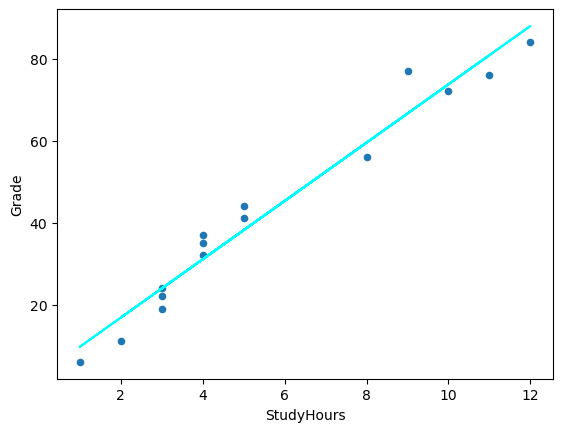

7.119103773584906 2.5330188679245254


In [27]:
from scipy import stats

df_regression = df_students[['StudyHours', 'Grade']].copy()

m, b, r, p, se = stats.linregress(df_regression['StudyHours'], df_regression['Grade'])

df_regression['fx'] = (m * df_regression['StudyHours']) + b

df_regression['error'] = df_regression['fx'] - df_regression['Grade']

df_regression.plot.scatter(x = 'StudyHours', y= 'Grade')

plt.plot(df_regression['StudyHours'], df_regression['fx'], color='Cyan')

plt.show()

print(m, b)

#### Creating a linear regression algorithm to pedict grade from hours studied

In [28]:
def predict(x):
    m = 7.1191
    b = 2.5330
    return m*x + b

prediction = predict(9)

prediction

66.6049